## Simulating Efron's Bootstrapping Experiment

We'll simulate the scenario Efron described: weighing 100 apples and 100 oranges, and then using bootstrapping to determine if the observed difference in means is statistically significant or merely due to random sampling.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Generate fake data for apples and oranges ---
# Let's assume apples are generally heavier than oranges, but with some overlap.
np.random.seed(42) # for reproducibility

num_samples = 100

# Apple weights (e.g., mean 180g, std dev 20g)
apple_weights = np.random.normal(loc=180, scale=20, size=num_samples)

# Orange weights (e.g., mean 150g, std dev 25g)
orange_weights = np.random.normal(loc=150, scale=25, size=num_samples)

print(f"Original Apple Mean: {np.mean(apple_weights):.2f}g")
print(f"Original Orange Mean: {np.mean(orange_weights):.2f}g")


Original Apple Mean: 177.92g
Original Orange Mean: 150.56g


### Bootstrapping Process

Now, let's implement Efron's idea. We'll resample with replacement from our original 100 apple and 100 orange weights many times (e.g., 1000 times) and calculate the mean for each resample. This will give us a distribution of means for both fruits.

In [ ]:
# --- 2. Implement the bootstrapping process ---
num_bootstraps = 1000

bootstrapped_apple_means = []
for _ in range(num_bootstraps):
    # Sample with replacement (bootstrapping)
    resample = np.random.choice(apple_weights, size=num_samples, replace=True)
    bootstrapped_apple_means.append(np.mean(resample))

bootstrapped_orange_means = []
for _ in range(num_bootstraps):
    resample = np.random.choice(orange_weights, size=num_samples, replace=True)
    bootstrapped_orange_means.append(np.mean(resample))

print(f"Generated {len(bootstrapped_apple_means)} bootstrapped means for apples.")
print(f"Generated {len(bootstrapped_orange_means)} bootstrapped means for oranges.")


Generated 1000 bootstrapped means for apples.
Generated 1000 bootstrapped means for oranges.


### Visualizing the Bootstrapped Means

Finally, let's visualize these distributions. If the distributions of the bootstrapped means are largely separate, it suggests that the true population means are likely different. If they overlap significantly, it implies that the observed difference could easily arise from random sampling.

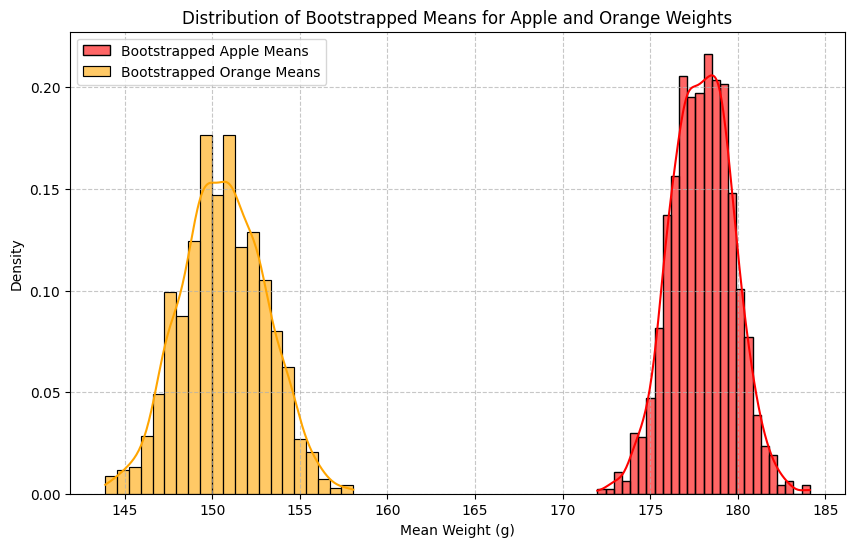

95% Confidence Interval for Apple Mean: (174.46g, 181.37g)
95% Confidence Interval for Orange Mean: (146.00g, 155.29g)

Based on the 95% confidence intervals, the means of apples and oranges appear to be significantly different.


In [ ]:
# --- 3. Visualize the distributions of the bootstrapped means ---
plt.figure(figsize=(10, 6))
sns.histplot(bootstrapped_apple_means, color='red', label='Bootstrapped Apple Means', kde=True, stat='density', alpha=0.6)
sns.histplot(bootstrapped_orange_means, color='orange', label='Bootstrapped Orange Means', kde=True, stat='density', alpha=0.6)

plt.title('Distribution of Bootstrapped Means for Apple and Orange Weights')
plt.xlabel('Mean Weight (g)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Calculate confidence intervals (e.g., 95%)
apple_ci_lower, apple_ci_upper = np.percentile(bootstrapped_apple_means, [2.5, 97.5])
orange_ci_lower, orange_ci_upper = np.percentile(bootstrapped_orange_means, [2.5, 97.5])

print(f"95% Confidence Interval for Apple Mean: ({apple_ci_lower:.2f}g, {apple_ci_upper:.2f}g)")
print(f"95% Confidence Interval for Orange Mean: ({orange_ci_lower:.2f}g, {orange_ci_upper:.2f}g)")

# Conclusion based on CI overlap
if apple_ci_lower > orange_ci_upper or orange_ci_lower > apple_ci_upper:
    print("\nBased on the 95% confidence intervals, the means of apples and oranges appear to be significantly different.")
else:
    print("\nBased on the 95% confidence intervals, there is significant overlap, suggesting the means might not be significantly different due to random chance.")
